In [1]:
# =============================================================
# CELL 1 — Install
# =============================================================
import subprocess
subprocess.run(["pip", "install", "-q",
                "transformers>=4.41.0", "albumentations",
                "torchmetrics", "timm"], check=False)

CompletedProcess(args=['pip', 'install', '-q', 'transformers>=4.41.0', 'albumentations', 'torchmetrics', 'timm'], returncode=0)

In [2]:
# =============================================================
# CELL 2 — Config + Paths
# =============================================================

import os
import io
import json
import time
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

# ── PATHS — change to match your local setup ──────────────────
DATASET_ROOT       = "/home/user1/jupyterlab/dataset1"
DATASET_IMAGE_DIR  = os.path.join(DATASET_ROOT, "images")
DATASET_ROOF_DIR   = os.path.join(DATASET_ROOT, "roof_masks")

# Segmentation baseline checkpoint (best model from your training)
SEG_CKPT_PATH      = "/home/user1/jupyterlab/segformer_ckpts1/best_model.pth"

# Where roof checkpoints will be saved
ROOF_CKPT_DIR      = "/home/user1/jupyterlab/segformer_roof_ckpts1"
os.makedirs(ROOF_CKPT_DIR, exist_ok=True)

CFG = {
    "num_seg_classes"  : 6,
    "num_roof_classes" : 5,        # 0=non-building, 1-4=roof types
    "image_size"       : 512,
    "crop_size"        : 448,
    "num_workers"      : 8,        # use more workers on local machine

    # Must match your seg training backbone exactly
    "backbone"         : "nvidia/mit-b3",
    "drop_path_rate"   : 0.1,

    "epochs"           : 30,       # roof head converges faster than full model
    "batch_size"       : 16,       # leverage full GPU
    "grad_accum_steps" : 1,
    "lr"               : 3e-4,     # higher LR — only roof head trains
    "weight_decay"     : 0.01,

    "device"           : "cuda" if torch.cuda.is_available() else "cpu",
    "use_amp"          : True,

    "seg_ckpt"         : SEG_CKPT_PATH,
    "checkpoint_dir"   : ROOF_CKPT_DIR,
}

ROOF_ID2LABEL = {
    0: "Non-building",
    1: "Roof-type-1",
    2: "Roof-type-2",
    3: "Roof-type-3",
    4: "Roof-type-4",
}

ROOF_COLORS = {
    0: (0,   0,   0),
    1: (220, 60,  60),
    2: (60,  60,  220),
    3: (60,  180, 60),
    4: (220, 160, 0),
}

print(f"Device : {CFG['device']}")
if CFG["device"] == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    try:
        vram = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f"VRAM   : {vram:.1f} GB")
    except:
        print("VRAM   : Unified memory (GB10)")
print("Config ready ✓")

Device : cuda
GPU    : NVIDIA GB10
VRAM   : 128.5 GB
Config ready ✓


In [3]:
# =============================================================
# CELL 3 — Splits + Pixel counts + Class weights
# =============================================================

from tqdm import tqdm
from sklearn.model_selection import train_test_split
import random

roof_splits_path     = os.path.join(ROOF_CKPT_DIR, "roof_splits.json")
roof_pixelcount_path = os.path.join(ROOF_CKPT_DIR, "roof_pixel_counts.npy")

# ── SCAN which tiles have roof annotations ────────────────────
scan_path = os.path.join(ROOF_CKPT_DIR, "roof_tile_scan.json")

if os.path.exists(scan_path):
    print("Loading tile scan from disk...")
    with open(scan_path) as f:
        scan = json.load(f)
    nonempty_ids = scan["nonempty"]
else:
    print("Scanning roof masks for non-empty tiles...")
    all_ids      = [os.path.splitext(f)[0]
                    for f in os.listdir(DATASET_IMAGE_DIR)
                    if f.endswith(".png")]
    nonempty_ids = []
    for fid in tqdm(all_ids, desc="Scanning"):
        roof_path_f = os.path.join(DATASET_ROOF_DIR, f"{fid}.png")
        if not os.path.exists(roof_path_f):
            continue
        mask = np.array(Image.open(roof_path_f))
        if (mask > 0).any():
            nonempty_ids.append(fid)
    scan = {"nonempty": nonempty_ids, "total": len(all_ids)}
    with open(scan_path, "w") as f:
        json.dump(scan, f)
    print(f"Scan saved → {scan_path}")

print(f"Tiles with roof annotations: {len(nonempty_ids)}")

# ── SPLITS ────────────────────────────────────────────────────
if os.path.exists(roof_splits_path):
    print("Loading roof splits from disk...")
    with open(roof_splits_path) as f:
        roof_splits = json.load(f)
    train_ids = roof_splits["train"]
    val_ids   = roof_splits["val"]
    test_ids  = roof_splits["test"]
else:
    print("Computing splits...")
    random.seed(42)
    random.shuffle(nonempty_ids)
    train_ids, temp_ids = train_test_split(
        nonempty_ids, test_size=0.20, random_state=42)
    val_ids, test_ids = train_test_split(
        temp_ids, test_size=0.50, random_state=42)
    roof_splits = {"train": train_ids,
                   "val":   val_ids,
                   "test":  test_ids}
    with open(roof_splits_path, "w") as f:
        json.dump(roof_splits, f)
    print(f"Splits saved → {roof_splits_path}")

print(f"Train: {len(train_ids)} | Val: {len(val_ids)} | Test: {len(test_ids)}")

# ── PIXEL COUNTS ──────────────────────────────────────────────
if os.path.exists(roof_pixelcount_path):
    print("Loading roof pixel counts from disk...")
    roof_pixel_counts = np.load(roof_pixelcount_path)
else:
    print("Counting roof pixels in training masks...")
    roof_pixel_counts = np.zeros(CFG["num_roof_classes"], dtype=np.float64)
    for fid in tqdm(train_ids, desc="Pixel count"):
        mask = np.array(Image.open(
            os.path.join(DATASET_ROOF_DIR, f"{fid}.png")))
        for c in range(CFG["num_roof_classes"]):
            roof_pixel_counts[c] += (mask == c).sum()
    np.save(roof_pixelcount_path, roof_pixel_counts)
    print(f"Saved → {roof_pixelcount_path}")

print("\nRoof pixel distribution:")
for c in range(CFG["num_roof_classes"]):
    pct = 100 * roof_pixel_counts[c] / roof_pixel_counts.sum()
    print(f"  [{c}] {ROOF_ID2LABEL[c]:15s}: {pct:.2f}%")

# ── CLASS WEIGHTS ─────────────────────────────────────────────
# Class 0 (non-building) is ignored entirely in loss
# Classes 1-4 get inverse-frequency weights, capped at 3x
# Consistent with seg training philosophy — no aggressive overweighting
building_counts = roof_pixel_counts[1:]
total_b         = building_counts.sum()
raw_w           = total_b / (4 * building_counts + 1e-6)
raw_w           = raw_w / raw_w.mean()
clamped_w       = np.clip(raw_w, 0.5, 3.0)   # same cap as seg training

full_weights    = np.concatenate([[0.0], clamped_w])
roof_weights_t  = torch.tensor(
    full_weights, dtype=torch.float32
).to(CFG["device"])

print("\nClass weights (0=ignored, 1-4=active):")
for c in range(CFG["num_roof_classes"]):
    print(f"  [{c}] {ROOF_ID2LABEL[c]:15s}: {full_weights[c]:.3f}")
print("\nCell 3 complete ✓")

Scanning roof masks for non-empty tiles...


Scanning: 100%|██████████| 8425/8425 [00:06<00:00, 1401.22it/s]


Scan saved → /home/user1/jupyterlab/segformer_roof_ckpts1/roof_tile_scan.json
Tiles with roof annotations: 5885
Computing splits...
Splits saved → /home/user1/jupyterlab/segformer_roof_ckpts1/roof_splits.json
Train: 4708 | Val: 588 | Test: 589
Counting roof pixels in training masks...


Pixel count: 100%|██████████| 4708/4708 [00:04<00:00, 1079.87it/s]


Saved → /home/user1/jupyterlab/segformer_roof_ckpts1/roof_pixel_counts.npy

Roof pixel distribution:
  [0] Non-building   : 65.09%
  [1] Roof-type-1    : 26.74%
  [2] Roof-type-2    : 0.59%
  [3] Roof-type-3    : 6.50%
  [4] Roof-type-4    : 1.07%

Class weights (0=ignored, 1-4=active):
  [0] Non-building   : 0.000
  [1] Roof-type-1    : 0.500
  [2] Roof-type-2    : 2.393
  [3] Roof-type-3    : 0.500
  [4] Roof-type-4    : 1.335

Cell 3 complete ✓


In [5]:
# =============================================================
# CELL 4 — Dataset + DataLoader
# =============================================================

import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomCrop(CFG["crop_size"], CFG["crop_size"], p=0.5),
    A.Resize(CFG["image_size"], CFG["image_size"]),

    A.OneOf([
        A.ColorJitter(
            brightness=0.4, contrast=0.4,
            saturation=0.3, hue=0.1,
        ),
        A.HueSaturationValue(
            hue_shift_limit=20,
            sat_shift_limit=30,
            val_shift_limit=20,
        ),
    ], p=0.7),

    A.RandomBrightnessContrast(
        brightness_limit=0.2, contrast_limit=0.2, p=0.4),
    A.GaussianBlur(blur_limit=3, p=0.3),
    A.GaussNoise(std_range=(0.012, 0.028), p=0.3),

    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
], additional_targets={"roof_mask": "mask"})

val_transform = A.Compose([
    A.Resize(CFG["image_size"], CFG["image_size"]),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
], additional_targets={"roof_mask": "mask"})


class RoofDataset(Dataset):
    def __init__(self, ids, image_dir, roof_dir, transform=None):
        self.ids       = ids
        self.image_dir = image_dir
        self.roof_dir  = roof_dir
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        fid       = self.ids[idx]
        image     = np.array(Image.open(
            os.path.join(self.image_dir, f"{fid}.png")
        ).convert("RGB"))
        roof_mask = np.clip(
            np.array(Image.open(
                os.path.join(self.roof_dir, f"{fid}.png"))),
            0, CFG["num_roof_classes"] - 1
        ).astype(np.int64)

        if self.transform:
            aug       = self.transform(image=image, roof_mask=roof_mask)
            image     = aug["image"]
            roof_mask = aug["roof_mask"]

        if isinstance(roof_mask, torch.Tensor):
            return image, roof_mask.clone().detach().long()
        return image, torch.tensor(roof_mask, dtype=torch.long)


train_ds = RoofDataset(train_ids, DATASET_IMAGE_DIR,
                       DATASET_ROOF_DIR, train_transform)
val_ds   = RoofDataset(val_ids,   DATASET_IMAGE_DIR,
                       DATASET_ROOF_DIR, val_transform)
test_ds  = RoofDataset(test_ids,  DATASET_IMAGE_DIR,
                       DATASET_ROOF_DIR, val_transform)

train_loader = DataLoader(
    train_ds, batch_size=CFG["batch_size"],
    shuffle=True,  num_workers=CFG["num_workers"],
    pin_memory=False, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=CFG["batch_size"],
    shuffle=False, num_workers=CFG["num_workers"],
    pin_memory=False,
)
test_loader = DataLoader(
    test_ds, batch_size=CFG["batch_size"],
    shuffle=False, num_workers=CFG["num_workers"],
    pin_memory=False,
)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")
print("Datasets ready ✓")

Train batches : 294
Val batches   : 37
Test batches  : 37
Datasets ready ✓


In [6]:
# =============================================================
# CELL 5 — Model: load seg baseline → build DualHead → freeze
# =============================================================

from transformers import SegformerForSemanticSegmentation


class RoofHead(nn.Module):
    """
    Lightweight segmentation head for roof type classification.
    Takes last encoder hidden state (B, C, H/32, W/32) as input.
    Outputs (B, num_roof_classes, H/32, W/32) — upsampled in training loop.
    """
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.head = nn.Sequential(
            nn.Conv2d(in_channels, 256, kernel_size=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, num_classes, kernel_size=1),
        )

    def forward(self, x):
        return self.head(x)


class DualHeadSegFormer(nn.Module):
    """
    Shares encoder with seg model.
    Encoder + seg_head frozen — only roof_head trains.
    """
    def __init__(self, seg_model, num_roof_classes):
        super().__init__()
        self.encoder   = seg_model.segformer
        self.seg_head  = seg_model.decode_head
        enc_out_dim    = seg_model.config.hidden_sizes[-1]
        self.roof_head = RoofHead(enc_out_dim, num_roof_classes)

    def forward(self, pixel_values):
        outputs = self.encoder(
            pixel_values,
            output_hidden_states=True,
            return_dict=True,
        )
        hidden_states = outputs.hidden_states
        seg_logits    = self.seg_head(hidden_states)
        roof_logits   = self.roof_head(hidden_states[-1])
        return seg_logits, roof_logits


# ── Load seg baseline checkpoint ──────────────────────────────
print(f"Loading seg baseline: {CFG['seg_ckpt']}")
assert os.path.exists(CFG["seg_ckpt"]), \
    f"Seg checkpoint not found: {CFG['seg_ckpt']}"

base_model = SegformerForSemanticSegmentation.from_pretrained(
    CFG["backbone"],
    num_labels=CFG["num_seg_classes"],
    ignore_mismatched_sizes=True,
    drop_path_rate=CFG["drop_path_rate"],
)

seg_ckpt = torch.load(
    CFG["seg_ckpt"], map_location=CFG["device"], weights_only=False
)
base_model.load_state_dict(seg_ckpt["model"])
print(f"Seg model loaded — best mIoU: {seg_ckpt.get('best_score', 'N/A'):.4f}")

# ── Build dual head ───────────────────────────────────────────
model = DualHeadSegFormer(
    base_model, CFG["num_roof_classes"]
).to(CFG["device"])

# ── Freeze encoder + seg head ─────────────────────────────────
# Only roof_head parameters will be updated
for param in model.encoder.parameters():
    param.requires_grad = False
for param in model.seg_head.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters()
                if p.requires_grad)
total_p   = sum(p.numel() for p in model.parameters())
print(f"Trainable : {trainable/1e6:.2f}M / {total_p/1e6:.1f}M params")
print("Encoder + seg head frozen ✓  |  Roof head trainable ✓")
print("Cell 5 complete ✓")

Loading seg baseline: /home/user1/jupyterlab/segformer_ckpts1/best_model.pth


You passed `num_labels=6` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 628/628 [00:00<00:00, 53636.26it/s]
SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.bias                               | UNEXPECTED | 
classifier.weight                             | UNEXPECTED | 
decode_head.batch_norm.running_mean           | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.batch_norm.running_va

Seg model loaded — best mIoU: 0.7182
Trainable : 0.43M / 47.7M params
Encoder + seg head frozen ✓  |  Roof head trainable ✓
Cell 5 complete ✓


In [7]:
# =============================================================
# CELL 6 — Loss + Optimizer + Scheduler
# =============================================================

from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts


class MaskedCELoss(nn.Module):
    """
    CE loss with ignore_index=0 — non-building pixels
    contribute zero gradient, model only learns roof types
    where buildings actually exist.
    """
    def __init__(self, weight):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weight, ignore_index=0)

    def forward(self, logits, targets):
        return self.ce(logits, targets)


roof_criterion = MaskedCELoss(weight=roof_weights_t)

# Only optimize roof_head parameters — encoder and seg_head frozen
optimizer = AdamW(
    [p for p in model.roof_head.parameters() if p.requires_grad],
    lr=CFG["lr"],
    weight_decay=CFG["weight_decay"],
)

# CosineAnnealingWarmRestarts — consistent with seg training
# T_0=10: first restart at epoch 10
# T_mult=2: second cycle = 20 epochs (10-30)
# Gives 2 restarts within 30 epochs
scheduler = CosineAnnealingWarmRestarts(
    optimizer,
    T_0=10,
    T_mult=2,
    eta_min=1e-6,
)

scaler = torch.amp.GradScaler("cuda", enabled=False)  # bfloat16 — no scaling needed

print(f"Optimizer   : AdamW — only roof_head params")
print(f"Scheduler   : CosineAnnealingWarmRestarts T_0=10 T_mult=2")
print(f"LR          : {CFG['lr']}")
print("Cell 6 complete ✓")

Optimizer   : AdamW — only roof_head params
Scheduler   : CosineAnnealingWarmRestarts T_0=10 T_mult=2
LR          : 0.0003
Cell 6 complete ✓


In [8]:
# =============================================================
# CELL 7 — Metrics
# =============================================================

from torchmetrics import JaccardIndex, Accuracy

# ignore_index=0 — non-building pixels not counted in IoU/accuracy
iou_metric = JaccardIndex(
    task="multiclass",
    num_classes=CFG["num_roof_classes"],
    average="none",
    ignore_index=0,
).to(CFG["device"])

acc_metric = Accuracy(
    task="multiclass",
    num_classes=CFG["num_roof_classes"],
    ignore_index=0,
).to(CFG["device"])

print("Metrics ready ✓")

Metrics ready ✓


In [9]:
# =============================================================
# CELL 8 — Checkpoint helpers
# =============================================================

def save_roof_checkpoint(epoch, model, optimizer, scheduler,
                         scaler, best_miou, history, path):
    tmp = path + ".tmp"
    torch.save({
        "epoch"     : epoch,
        "roof_head" : model.roof_head.state_dict(),
        "optimizer" : optimizer.state_dict(),
        "scheduler" : scheduler.state_dict(),
        "scaler"    : scaler.state_dict(),
        "best_miou" : best_miou,
        "history"   : history,
    }, tmp)
    os.replace(tmp, path)
    print(f"  → Saved: {os.path.basename(path)}")


print("Checkpoint helpers ready ✓")


Checkpoint helpers ready ✓


In [10]:
# =============================================================
# CELL 9 — Training loop
# =============================================================

from tqdm import tqdm

start_epoch = 0
best_miou   = 0.0
history     = []


def train_one_epoch(epoch):
    model.train()
    # Keep frozen layers in eval mode so BatchNorm stats stay fixed
    model.encoder.eval()
    model.seg_head.eval()
    iou_metric.reset()
    acc_metric.reset()
    running_loss = 0.0
    optimizer.zero_grad()

    for step, (images, roof_masks) in enumerate(
            tqdm(train_loader, desc=f"Epoch {epoch+1} train", leave=True)):

        images     = images.to(CFG["device"],     non_blocking=True)
        roof_masks = roof_masks.to(CFG["device"], non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.bfloat16,
                                 enabled=CFG["use_amp"]):
            _, roof_logits = model(images)
            roof_up = F.interpolate(
                roof_logits,
                size=(CFG["image_size"], CFG["image_size"]),
                mode="bilinear", align_corners=False,
            )
            loss = roof_criterion(roof_up, roof_masks) \
                   / CFG["grad_accum_steps"]

        scaler.scale(loss).backward()
        running_loss += loss.item() * CFG["grad_accum_steps"]

        if (step + 1) % CFG["grad_accum_steps"] == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.roof_head.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        with torch.no_grad():
            iou_metric.update(roof_up.argmax(dim=1), roof_masks)
            acc_metric.update(roof_up.argmax(dim=1), roof_masks)

    per_iou = iou_metric.compute().cpu().numpy()
    return (
        running_loss / len(train_loader),
        float(per_iou[1:].mean()),   # mean IoU over roof types 1-4 only
        acc_metric.compute().item(),
        per_iou,
    )


@torch.no_grad()
def validate(loader, split="val"):
    model.eval()
    iou_metric.reset()
    acc_metric.reset()
    running_loss = 0.0

    for images, roof_masks in tqdm(loader, desc=f"  {split}", leave=True):
        images     = images.to(CFG["device"],     non_blocking=True)
        roof_masks = roof_masks.to(CFG["device"], non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.bfloat16,
                                 enabled=CFG["use_amp"]):
            _, roof_logits = model(images)
            roof_up = F.interpolate(
                roof_logits,
                size=(CFG["image_size"], CFG["image_size"]),
                mode="bilinear", align_corners=False,
            )
            loss = roof_criterion(roof_up, roof_masks)

        running_loss += loss.item()
        iou_metric.update(roof_up.argmax(dim=1), roof_masks)
        acc_metric.update(roof_up.argmax(dim=1), roof_masks)

    per_iou = iou_metric.compute().cpu().numpy()
    return (
        running_loss / len(loader),
        float(per_iou[1:].mean()),
        acc_metric.compute().item(),
        per_iou,
    )


# ── Main loop ─────────────────────────────────────────────────
print("=" * 55)
print("Roof head training started")
print(f"Epochs: {CFG['epochs']} | Batch: {CFG['batch_size']} | LR: {CFG['lr']}")
print("=" * 55)

for epoch in range(start_epoch, CFG["epochs"]):
    t0 = time.time()

    tr_loss, tr_miou, tr_acc, tr_iou = train_one_epoch(epoch)
    vl_loss, vl_miou, vl_acc, vl_iou = validate(val_loader, "val")

    scheduler.step()   # CosineAnnealingWarmRestarts — once per epoch

    elapsed = time.time() - t0

    history.append({
        "epoch"  : epoch + 1,
        "tr_loss": tr_loss,
        "tr_miou": tr_miou,
        "vl_loss": vl_loss,
        "vl_miou": vl_miou,
        "vl_iou" : vl_iou.tolist(),
        "time_s" : elapsed,
    })

    print(f"\nEpoch {epoch+1:02d}/{CFG['epochs']} — {elapsed/60:.1f} min")
    print(f"  Train  loss={tr_loss:.4f}  mIoU={tr_miou:.4f}  acc={tr_acc:.4f}")
    print(f"  Val    loss={vl_loss:.4f}  mIoU={vl_miou:.4f}  acc={vl_acc:.4f}")
    print("  Val IoU per roof class:")
    for c in range(1, CFG["num_roof_classes"]):
        bar = "█" * int(vl_iou[c] * 25)
        print(f"    [{c}] {ROOF_ID2LABEL[c]:15s}: {vl_iou[c]:.4f}  {bar}")

    # Save epoch checkpoint
    ep_path = os.path.join(ROOF_CKPT_DIR, f"roof_epoch_{epoch+1:02d}.pth")
    save_roof_checkpoint(epoch, model, optimizer, scheduler,
                         scaler, best_miou, history, ep_path)

    # Save best
    if vl_miou > best_miou:
        best_miou = vl_miou
        best_path = os.path.join(ROOF_CKPT_DIR, "best_roof_model.pth")
        save_roof_checkpoint(epoch, model, optimizer, scheduler,
                             scaler, best_miou, history, best_path)
        print(f"  ★ New best roof mIoU: {best_miou:.4f}")

    # Keep only last 3 epoch checkpoints
    old = sorted([
        f for f in os.listdir(ROOF_CKPT_DIR)
        if f.startswith("roof_epoch_") and f.endswith(".pth")
    ])
    for f in old[:-3]:
        os.remove(os.path.join(ROOF_CKPT_DIR, f))

print(f"\nTraining complete! Best val mIoU: {best_miou:.4f}")

Roof head training started
Epochs: 30 | Batch: 16 | LR: 0.0003


  val: 100%|██████████| 37/37 [00:20<00:00,  1.82it/s]



Epoch 01/30 — 3.2 min
  Train  loss=0.3575  mIoU=0.6077  acc=0.9192
  Val    loss=0.2822  mIoU=0.6290  acc=0.9261
  Val IoU per roof class:
    [1] Roof-type-1    : 0.9253  ███████████████████████
    [2] Roof-type-2    : 0.4912  ████████████
    [3] Roof-type-3    : 0.7937  ███████████████████
    [4] Roof-type-4    : 0.3057  ███████
  → Saved: roof_epoch_01.pth
  → Saved: best_roof_model.pth
  ★ New best roof mIoU: 0.6290


  val: 100%|██████████| 37/37 [00:20<00:00,  1.79it/s]



Epoch 02/30 — 3.2 min
  Train  loss=0.2770  mIoU=0.6748  acc=0.9358
  Val    loss=0.2558  mIoU=0.7020  acc=0.9419
  Val IoU per roof class:
    [1] Roof-type-1    : 0.9358  ███████████████████████
    [2] Roof-type-2    : 0.6603  ████████████████
    [3] Roof-type-3    : 0.8420  █████████████████████
    [4] Roof-type-4    : 0.3700  █████████
  → Saved: roof_epoch_02.pth
  → Saved: best_roof_model.pth
  ★ New best roof mIoU: 0.7020


  val: 100%|██████████| 37/37 [00:20<00:00,  1.83it/s]


... (51 outputs left out)

  val: 100%|██████████| 37/37 [00:20<00:00,  1.81it/s]



Epoch 29/30 — 3.2 min
  Train  loss=0.1166  mIoU=0.8332  acc=0.9667
  Val    loss=0.2710  mIoU=0.7170  acc=0.9484
  Val IoU per roof class:
    [1] Roof-type-1    : 0.9433  ███████████████████████
    [2] Roof-type-2    : 0.6513  ████████████████
    [3] Roof-type-3    : 0.8529  █████████████████████
    [4] Roof-type-4    : 0.4204  ██████████
  → Saved: roof_epoch_29.pth


  val: 100%|██████████| 37/37 [00:20<00:00,  1.81it/s]


Epoch 30/30 — 3.2 min
  Train  loss=0.1170  mIoU=0.8344  acc=0.9667
  Val    loss=0.2690  mIoU=0.7157  acc=0.9480
  Val IoU per roof class:
    [1] Roof-type-1    : 0.9432  ███████████████████████
    [2] Roof-type-2    : 0.6531  ████████████████
    [3] Roof-type-3    : 0.8515  █████████████████████
    [4] Roof-type-4    : 0.4149  ██████████
  → Saved: roof_epoch_30.pth

Training complete! Best val mIoU: 0.7218


Running combined inference on 3 random test images...

Tile: 5279


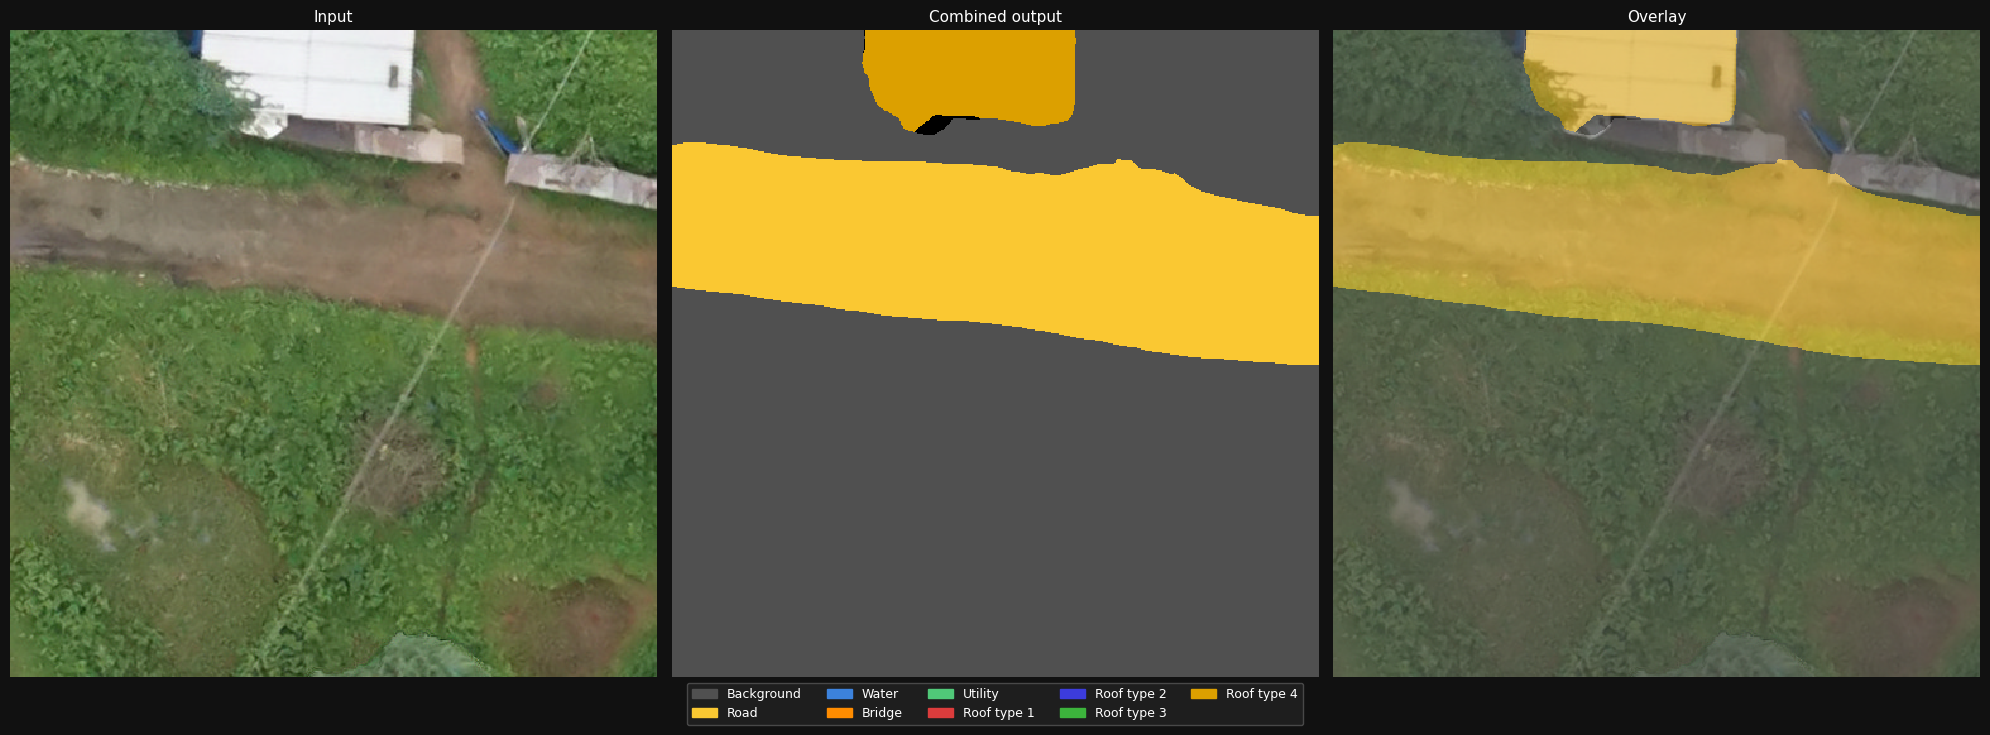


Tile: 7316


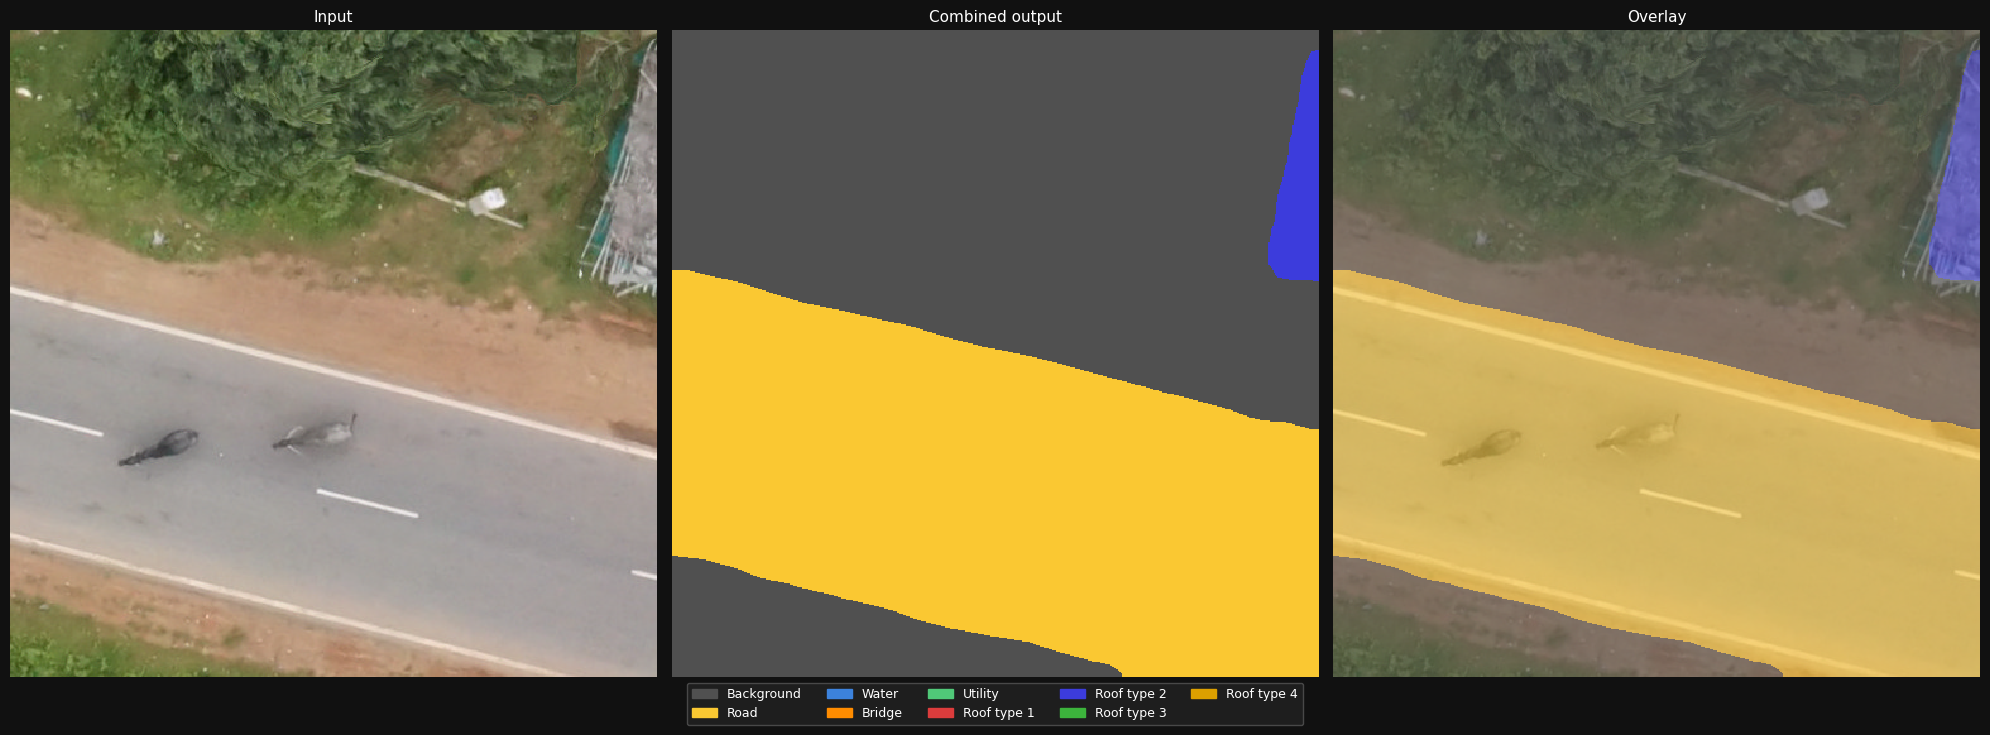


Tile: 3755


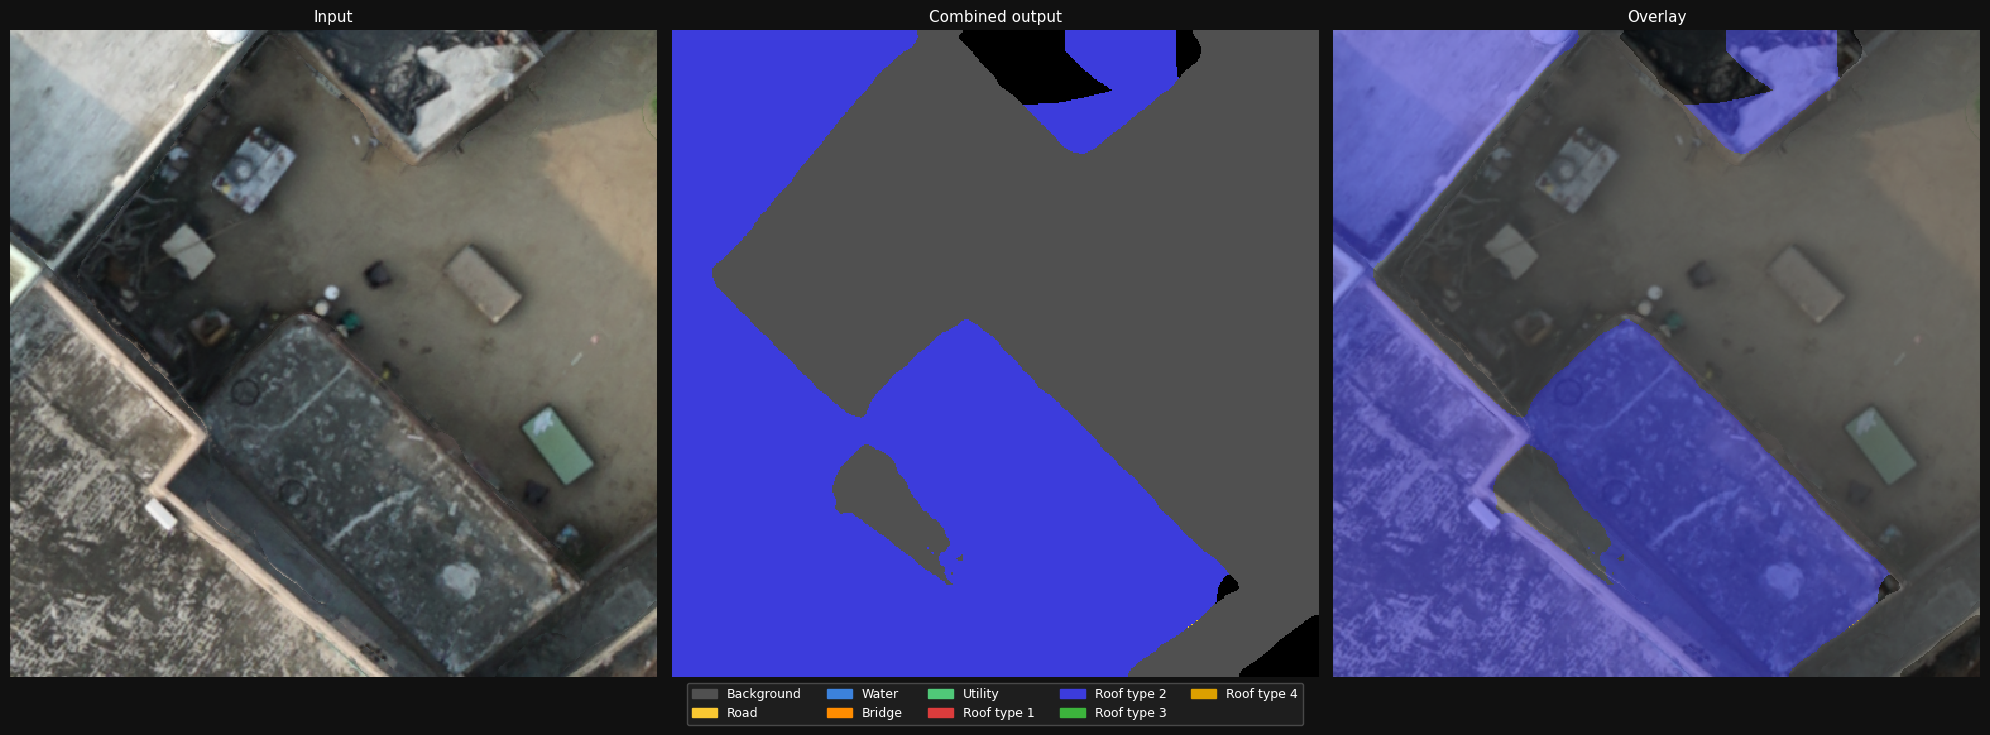

In [21]:
# =============================================================
# CELL 10 — Combined inference visualization
# =============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random

def predict_combined(image_path):
    """
    Run both seg + roof heads on a single image.
    Returns combined coloured overlay.
    """
    image = np.array(Image.open(image_path).convert("RGB"))
    h, w  = image.shape[:2]

    infer_t = A.Compose([
        A.Resize(CFG["image_size"], CFG["image_size"]),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])
    img_t = infer_t(image=image)["image"] \
                .unsqueeze(0).to(CFG["device"])

    model.eval()
    with torch.no_grad(), torch.amp.autocast(
            "cuda", dtype=torch.bfloat16, enabled=CFG["use_amp"]):
        seg_logits, roof_logits = model(img_t)
        seg_up  = F.interpolate(seg_logits,  size=(h, w),
                                mode="bilinear", align_corners=False)
        roof_up = F.interpolate(roof_logits, size=(h, w),
                                mode="bilinear", align_corners=False)

    seg_pred  = seg_up.argmax(dim=1).squeeze().cpu().numpy()
    roof_pred = roof_up.argmax(dim=1).squeeze().cpu().numpy()

    # Combined: building pixels replaced by roof type (10-13)
    combined = seg_pred.copy().astype(np.int32)
    bldg_px  = (seg_pred == 1)
    combined[bldg_px] = 10 + roof_pred[bldg_px]

    combined_colors = {
        0 : (80,  80,  80),    # Background
        2 : (250, 200, 50),    # Road
        3 : (60,  130, 220),   # Water
        4 : (255, 140, 0),     # Bridge
        5 : (80,  200, 120),   # Utility
        10: (220, 60,  60),    # Roof type 1
        11: (60,  60,  220),   # Roof type 2
        12: (60,  180, 60),    # Roof type 3
        13: (220, 160, 0),     # Roof type 4
    }
    label_map = {
        0 : "Background",
        2 : "Road",
        3 : "Water",
        4 : "Bridge",
        5 : "Utility",
        10: "Roof type 1",
        11: "Roof type 2",
        12: "Roof type 3",
        13: "Roof type 4",
    }

    color_out = np.zeros((*combined.shape, 3), dtype=np.uint8)
    for val, color in combined_colors.items():
        color_out[combined == val] = color

    overlay = (image * 0.45 + color_out * 0.55).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(20, 7),
                              facecolor="#111111")
    fig.patch.set_facecolor("#111111")

    for ax, img, title in [
        (axes[0], image,     "Input"),
        (axes[1], color_out, "Combined output"),
        (axes[2], overlay,   "Overlay"),
    ]:
        ax.set_facecolor("#111111")
        ax.imshow(img, interpolation="nearest")
        ax.set_title(title, color="white", fontsize=11)
        ax.axis("off")

    patches = [
        mpatches.Patch(color=np.array(c)/255, label=label_map[i])
        for i, c in combined_colors.items()
    ]
    fig.legend(handles=patches, loc="lower center", ncol=5,
               bbox_to_anchor=(0.5, -0.04), fontsize=9,
               labelcolor="white", facecolor="#222",
               edgecolor="#555")
    plt.tight_layout()
    plt.show()

    return seg_pred, roof_pred, combined


# ── Quick test on random val images ──────────────────────────
print("Running combined inference on 3 random test images...")
sample_ids = random.sample(test_ids, min(3, len(test_ids)))

for fid in sample_ids:
    img_path = os.path.join(DATASET_IMAGE_DIR, f"{fid}.png")
    print(f"\nTile: {fid}")
    seg_out, roof_out, combined = predict_combined(img_path)